# SEG03 Compact U-Net for Crack Segmentation

**Course Instructor**  
Dr. Md Rifat Ahmmad Rashid  
Associate Professor  
East West University Bangladesh

## Notebook Focus

This notebook builds a PyTorch binary segmentation pipeline for the same Kaggle crack segmentation dataset used in SEG01 and SEG02.

The model is trained for **10 epochs** and uses a compact U-Net to keep runtime manageable in Kaggle. This notebook is **not optimized for final publication-level performance**; it is an instructional baseline for understanding image-mask datasets, U-Net design, loss functions, validation metrics, threshold calibration, and prediction visualization.

## Learning Goals

1. Build a crack image-mask PyTorch dataset.
2. Implement a compact U-Net encoder-decoder with skip connections.
3. Train and evaluate the model with BCE, Dice loss, IoU, and Dice score.
4. Plot train/validation loss and Dice curves.
5. Visualize predictions, ground truth masks, probability maps, thresholded masks, and failure cases.

## Expected Outputs

1. U-Net architecture summary.
2. Training and validation curves.
3. Prediction grids with image, ground truth mask, probability map, and thresholded mask.
4. Dice and IoU table for the validation split.
5. Failure-case analysis.

## 1. Environment Setup

In [1]:
# Core libraries
import os
import random
import time
from pathlib import Path
from collections import defaultdict

# Numerical, table, and visualization libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Progress bars
from tqdm.auto import tqdm

# PyTorch libraries
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Fixed input size allows cuDNN to select faster kernels on GPU.
torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Mixed precision enabled:", USE_AMP)

Device: cuda
GPU: Tesla T4
Mixed precision enabled: True


## 2. Configuration

The primary dataset path follows the same Kaggle setting:

`/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/images`

Fallback paths are included because Kaggle sometimes exposes datasets with shorter input names.

In [2]:
# Dataset root candidates. The first existing path will be used.
DATASET_CANDIDATES = [
    Path("/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset"),
    Path("/kaggle/input/crack-segmentation-dataset/crack_segmentation_dataset"),
    Path("/kaggle/input/crack-segmentation-dataset"),
    Path("/kaggle/input"),
]

# Compact instructional configuration.
IMAGE_SIZE = 256
MAX_SAMPLES = 800          # Set to None to use all discovered image-mask pairs.
VAL_RATIO = 0.20
BATCH_SIZE = 8
NUM_WORKERS = 2
EPOCHS = 30
BASE_CHANNELS = 32
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DEFAULT_THRESHOLD = 0.50

print("Image size:", IMAGE_SIZE)
print("Max samples:", MAX_SAMPLES)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)

Image size: 256
Max samples: 800
Epochs: 30
Batch size: 8


## 3. Discover Image-Mask Pairs

The code searches common `images`, `masks`, `train`, `test`, `valid`, and `labels` folders. It pairs images and masks by normalized file stem.

In [3]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
MASK_HINTS = {"mask", "masks", "label", "labels", "gt", "groundtruth", "ground_truth", "annotations"}


def find_dataset_root(candidates):
    """Return the first existing dataset root."""
    for p in candidates:
        if p.exists():
            return p
    raise FileNotFoundError("Dataset root was not found. Attach the Kaggle dataset first.")


def normalize_stem(path):
    """Normalize common image-mask naming differences."""
    stem = path.stem.lower()
    suffixes = ["_mask", "-mask", "_masks", "-masks", "_gt", "-gt", "_label", "-label",
                "_labels", "-labels", "_groundtruth", "-groundtruth", "_ground_truth", "-ground_truth"]
    for suffix in suffixes:
        if stem.endswith(suffix):
            stem = stem[:-len(suffix)]
    return stem


def has_mask_hint(path):
    """Return True if path name or parent folders suggest that the file is a mask."""
    parts = [x.lower() for x in path.parts]
    stem = path.stem.lower()
    return any(h in parts for h in MASK_HINTS) or any(h in stem for h in MASK_HINTS)


def collect_files(folder):
    """Collect image-like files from a folder."""
    return [p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS]


def discover_pairs(root):
    """Discover image-mask pairs from a crack segmentation dataset directory."""
    root = Path(root)

    image_dirs = [p for p in [root/"images", root/"Images", root/"image", root/"train"/"images",
                              root/"test"/"images", root/"valid"/"images", root/"val"/"images"] if p.exists()]
    mask_dirs = [p for p in [root/"masks", root/"Masks", root/"mask", root/"labels", root/"label",
                             root/"train"/"masks", root/"test"/"masks", root/"valid"/"masks", root/"val"/"masks"] if p.exists()]

    # Preferred case: images and masks are in separate folders.
    if image_dirs and mask_dirs:
        images, masks = [], []
        for d in image_dirs:
            images.extend(collect_files(d))
        for d in mask_dirs:
            masks.extend(collect_files(d))
    else:
        # Fallback case: recursively scan the root and infer mask files from names/folders.
        all_files = [p for p in tqdm(list(root.rglob("*")), desc="Scanning dataset")
                     if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
        masks = [p for p in all_files if has_mask_hint(p)]
        images = [p for p in all_files if not has_mask_hint(p)]

    # Build mask lookup using normalized stems.
    mask_lookup = defaultdict(list)
    for m in masks:
        mask_lookup[normalize_stem(m)].append(m)
        mask_lookup[m.stem.lower()].append(m)

    pairs, unmatched = [], []
    for img in tqdm(images, desc="Pairing images and masks"):
        candidates = mask_lookup.get(normalize_stem(img), []) or mask_lookup.get(img.stem.lower(), [])
        if candidates:
            pairs.append((img, candidates[0]))
        else:
            unmatched.append(img)

    pairs = sorted(set(pairs), key=lambda x: str(x[0]))
    return pairs, images, masks, unmatched


DATASET_ROOT = find_dataset_root(DATASET_CANDIDATES)
print("Selected dataset root:", DATASET_ROOT)

pairs, discovered_images, discovered_masks, unmatched_images = discover_pairs(DATASET_ROOT)
print("Discovered images:", len(discovered_images))
print("Discovered masks :", len(discovered_masks))
print("Paired samples   :", len(pairs))
print("Unmatched images :", len(unmatched_images))

if len(pairs) == 0:
    raise RuntimeError("No image-mask pairs were found. Check the Kaggle input path and mask naming pattern.")

for img_path, mask_path in pairs[:5]:
    print("IMAGE:", img_path)
    print("MASK :", mask_path)
    print("-" * 70)

Selected dataset root: /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset


Pairing images and masks:   0%|          | 0/22596 [00:00<?, ?it/s]

Discovered images: 22596
Discovered masks : 22596
Paired samples   : 22596
Unmatched images : 0
IMAGE: /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/images/CFD_001.jpg
MASK : /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/masks/CFD_001.jpg
----------------------------------------------------------------------
IMAGE: /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/images/CFD_002.jpg
MASK : /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/masks/CFD_002.jpg
----------------------------------------------------------------------
IMAGE: /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/images/CFD_003.jpg
MASK : /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/masks/CFD_003.jpg
---------------------------------------------------------------

## 4. Visual Check of Dataset Pairing

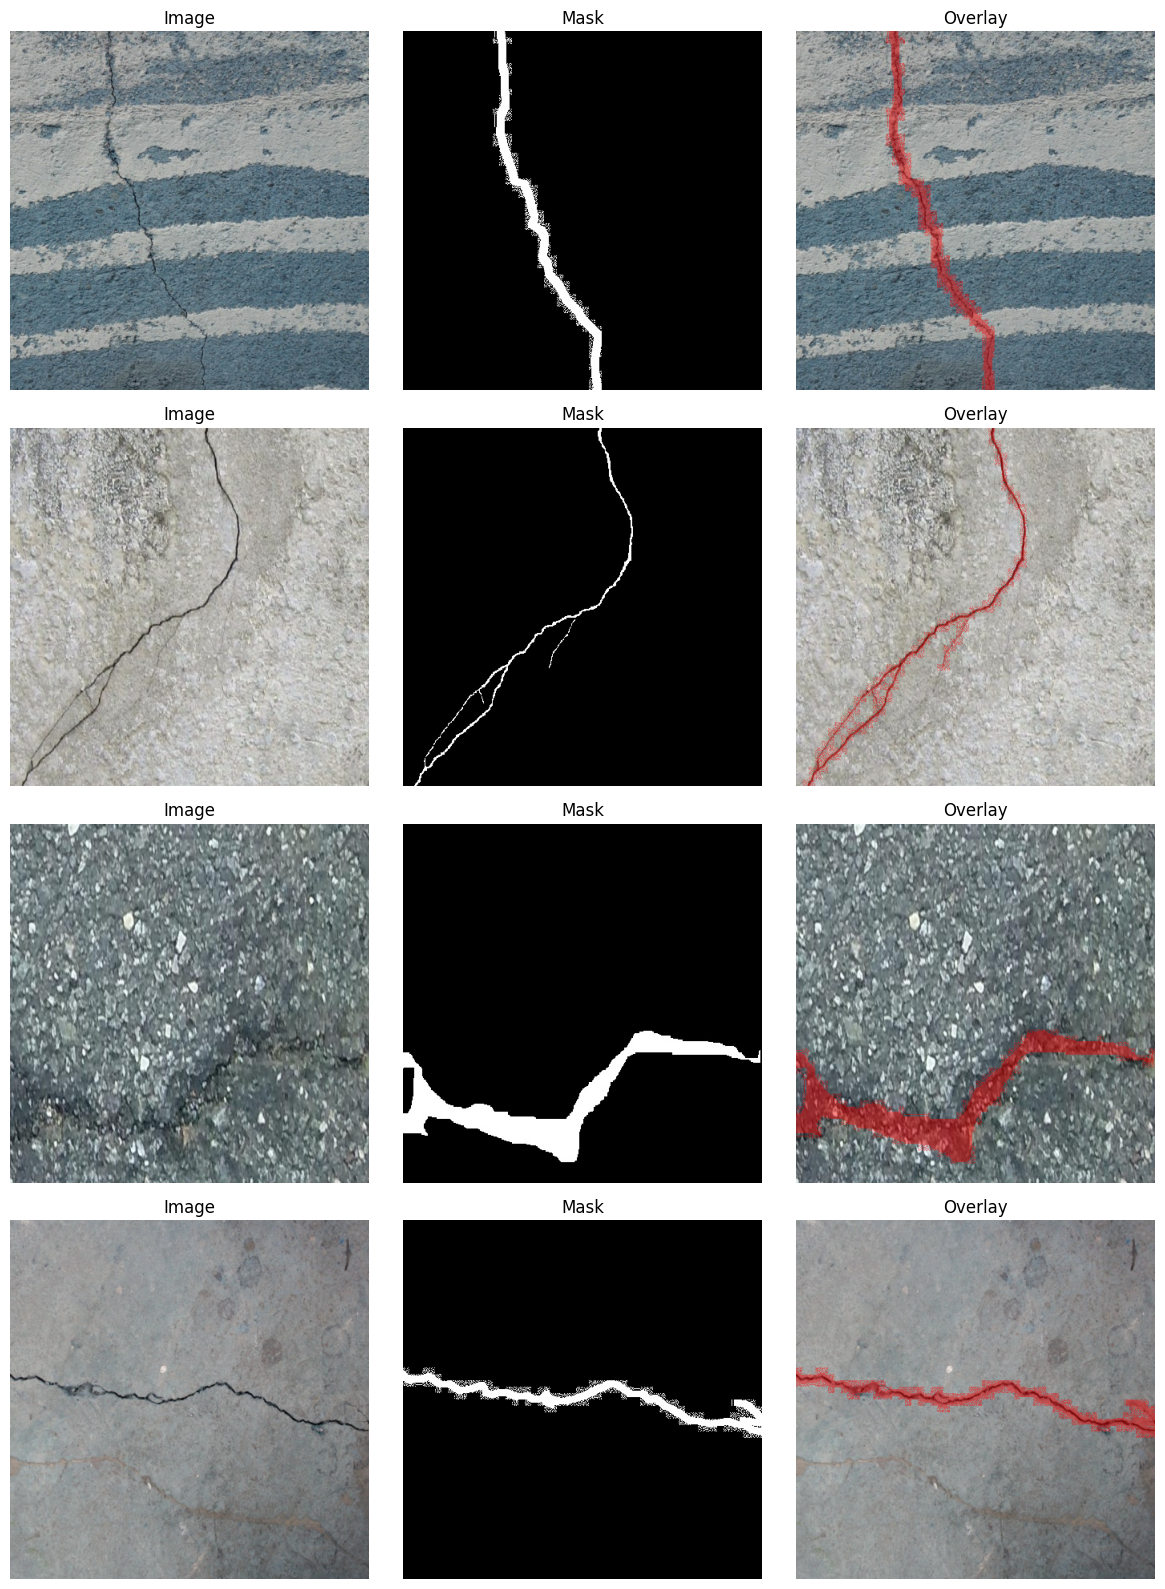

In [4]:
def load_rgb(path):
    """Load RGB image."""
    return Image.open(path).convert("RGB")


def load_mask(path):
    """Load mask as grayscale image."""
    return Image.open(path).convert("L")


def overlay_mask(image, mask, alpha=0.45):
    """Create red foreground overlay for mask pixels."""
    img = np.array(image).copy()
    m = np.array(mask) > 0
    red = img.copy()
    red[m] = [255, 0, 0]
    return (img * (1 - alpha) + red * alpha).astype(np.uint8)


def show_pair_grid(pairs, n=4):
    """Display image, ground-truth mask, and overlay."""
    selected = random.sample(pairs, k=min(n, len(pairs)))
    fig, axes = plt.subplots(len(selected), 3, figsize=(12, 4 * len(selected)))
    if len(selected) == 1:
        axes = np.expand_dims(axes, 0)

    for r, (img_path, mask_path) in enumerate(selected):
        img = load_rgb(img_path)
        mask = load_mask(mask_path)
        axes[r, 0].imshow(img); axes[r, 0].set_title("Image"); axes[r, 0].axis("off")
        axes[r, 1].imshow(mask, cmap="gray"); axes[r, 1].set_title("Mask"); axes[r, 1].axis("off")
        axes[r, 2].imshow(overlay_mask(img, mask)); axes[r, 2].set_title("Overlay"); axes[r, 2].axis("off")

    plt.tight_layout()
    plt.show()

show_pair_grid(pairs, n=4)

## 5. PyTorch Dataset and DataLoader

Each sample returns an image tensor `[3, H, W]` and a binary mask tensor `[1, H, W]`. Simple synchronized augmentations are applied during training.

In [5]:
class CrackSegmentationDataset(Dataset):
    """PyTorch dataset for crack image-mask pairs."""
    def __init__(self, pairs, image_size=256, augment=False):
        self.pairs = list(pairs)
        self.image_size = image_size
        self.augment = augment

    def __len__(self):
        return len(self.pairs)

    def _augment(self, image, mask):
        """Apply lightweight synchronized augmentations."""
        if random.random() < 0.5:
            image, mask = TF.hflip(image), TF.hflip(mask)
        if random.random() < 0.2:
            image, mask = TF.vflip(image), TF.vflip(mask)
        if random.random() < 0.3:
            angle = random.choice([90, 180, 270])
            image, mask = TF.rotate(image, angle), TF.rotate(mask, angle)
        if random.random() < 0.3:
            image = TF.adjust_brightness(image, random.uniform(0.85, 1.15))
            image = TF.adjust_contrast(image, random.uniform(0.85, 1.15))
        return image, mask

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]
        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        # Resize with bilinear interpolation for images and nearest-neighbor for masks.
        image = TF.resize(image, [self.image_size, self.image_size], interpolation=TF.InterpolationMode.BILINEAR)
        mask = TF.resize(mask, [self.image_size, self.image_size], interpolation=TF.InterpolationMode.NEAREST)

        if self.augment:
            image, mask = self._augment(image, mask)

        image = TF.to_tensor(image)
        mask = TF.to_tensor(mask)
        mask = (mask > 0.5).float()  # Convert grayscale mask to binary tensor.
        return image, mask


# Use a subset to keep training time suitable for a lab notebook.
all_pairs = pairs.copy()
random.shuffle(all_pairs)
if MAX_SAMPLES is not None:
    all_pairs = all_pairs[:min(MAX_SAMPLES, len(all_pairs))]

val_size = max(1, int(len(all_pairs) * VAL_RATIO))
train_pairs = all_pairs[:-val_size]
val_pairs = all_pairs[-val_size:]

train_dataset = CrackSegmentationDataset(train_pairs, image_size=IMAGE_SIZE, augment=True)
val_dataset = CrackSegmentationDataset(val_pairs, image_size=IMAGE_SIZE, augment=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                          pin_memory=torch.cuda.is_available(), persistent_workers=NUM_WORKERS > 0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
                        pin_memory=torch.cuda.is_available(), persistent_workers=NUM_WORKERS > 0)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training samples: 640
Validation samples: 160
Training batches: 80
Validation batches: 20


## 6. DataLoader Sanity Check

Image batch shape: torch.Size([8, 3, 256, 256])
Mask batch shape : torch.Size([8, 1, 256, 256])
Foreground ratio : 0.0212860107421875


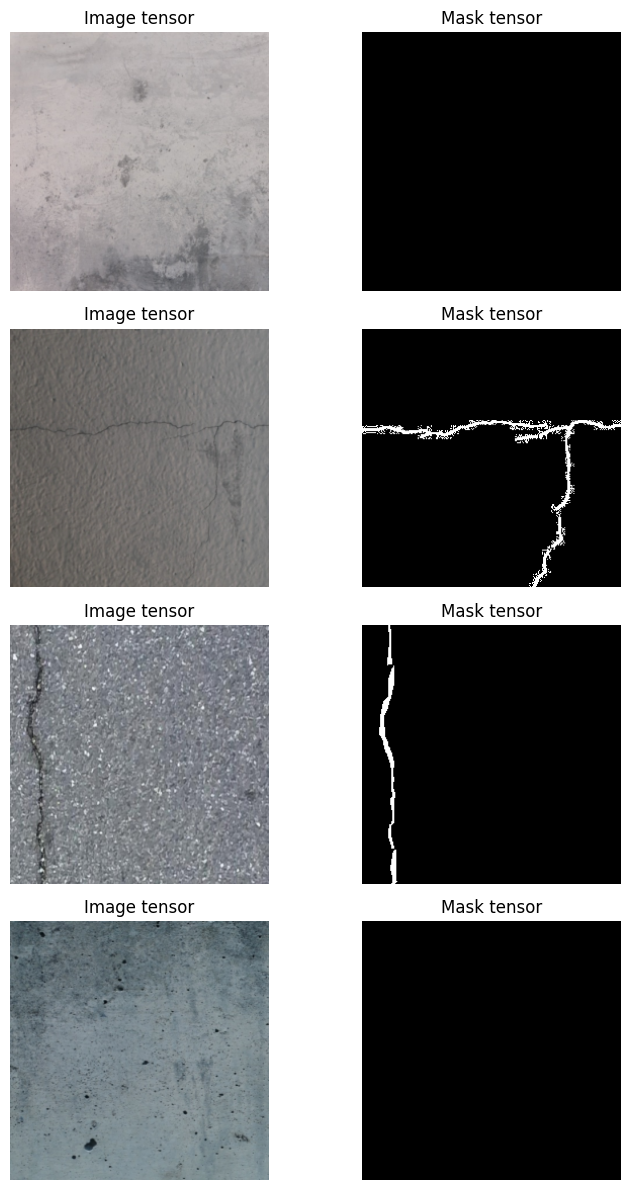

In [6]:
images, masks = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Mask batch shape :", masks.shape)
print("Foreground ratio :", float(masks.mean()))

fig, axes = plt.subplots(4, 2, figsize=(8, 12))
for i in range(min(4, images.shape[0])):
    axes[i, 0].imshow(images[i].permute(1, 2, 0)); axes[i, 0].set_title("Image tensor"); axes[i, 0].axis("off")
    axes[i, 1].imshow(masks[i, 0], cmap="gray"); axes[i, 1].set_title("Mask tensor"); axes[i, 1].axis("off")
plt.tight_layout(); plt.show()

## 7. Compact U-Net from Scratch

In [7]:
class DoubleConv(nn.Module):
    """Two Conv-BatchNorm-ReLU layers."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.net(x)


class Down(nn.Module):
    """Max-pooling followed by DoubleConv."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(nn.MaxPool2d(2), DoubleConv(in_ch, out_ch))
    def forward(self, x):
        return self.net(x)


class Up(nn.Module):
    """Upsampling, skip concatenation, and DoubleConv."""
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, 2, stride=2)
        self.conv = DoubleConv(out_ch + skip_ch, out_ch)
    def forward(self, x, skip):
        x = self.up(x)
        # Pad if spatial sizes differ by one pixel.
        dy, dx = skip.size(2) - x.size(2), skip.size(3) - x.size(3)
        x = F.pad(x, [dx // 2, dx - dx // 2, dy // 2, dy - dy // 2])
        return self.conv(torch.cat([skip, x], dim=1))


class CompactUNet(nn.Module):
    """Compact U-Net for binary crack segmentation."""
    def __init__(self, in_channels=3, out_channels=1, base=32):
        super().__init__()
        self.inc = DoubleConv(in_channels, base)
        self.d1 = Down(base, base * 2)
        self.d2 = Down(base * 2, base * 4)
        self.d3 = Down(base * 4, base * 8)
        self.bottom = Down(base * 8, base * 16)
        self.u3 = Up(base * 16, base * 8, base * 8)
        self.u2 = Up(base * 8, base * 4, base * 4)
        self.u1 = Up(base * 4, base * 2, base * 2)
        self.u0 = Up(base * 2, base, base)
        self.out = nn.Conv2d(base, out_channels, 1)
    def forward(self, x):
        x0 = self.inc(x)
        x1 = self.d1(x0)
        x2 = self.d2(x1)
        x3 = self.d3(x2)
        xb = self.bottom(x3)
        x = self.u3(xb, x3)
        x = self.u2(x, x2)
        x = self.u1(x, x1)
        x = self.u0(x, x0)
        return self.out(x)


model = CompactUNet(base=BASE_CHANNELS).to(device)
print(model)
print("Total parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

# Optional summary when torchinfo exists in the environment.
try:
    from torchinfo import summary
    summary(model, input_size=(1, 3, IMAGE_SIZE, IMAGE_SIZE))
except Exception as e:
    print("torchinfo summary skipped:", e)

CompactUNet(
  (inc): DoubleConv(
    (net): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (d1): Down(
    (net): Sequential(
      (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (1): DoubleConv(
        (net): Sequential(
          (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
          (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (4): BatchNorm2d

## 8. Losses and Metrics

The notebook defines BCE, Dice, focal, and combined loss. Training uses **BCEWithLogitsLoss + Dice loss**.

In [8]:
def dice_loss_from_logits(logits, targets, smooth=1.0):
    """Dice loss computed from sigmoid probabilities."""
    probs = torch.sigmoid(logits).view(logits.size(0), -1)
    targets = targets.view(targets.size(0), -1)
    inter = (probs * targets).sum(dim=1)
    denom = probs.sum(dim=1) + targets.sum(dim=1)
    dice = (2 * inter + smooth) / (denom + smooth)
    return 1 - dice.mean()


class FocalLossWithLogits(nn.Module):
    """Optional focal loss for class imbalance experiments."""
    def __init__(self, alpha=0.25, gamma=2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma
    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        probs = torch.sigmoid(logits)
        pt = torch.where(targets == 1, probs, 1 - probs)
        return (self.alpha * (1 - pt).pow(self.gamma) * bce).mean()


class BCEDiceLoss(nn.Module):
    """Combined BCE and Dice loss."""
    def __init__(self, pos_weight=None, bce_weight=0.5, dice_weight=0.5):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
        self.bce_weight = bce_weight
        self.dice_weight = dice_weight
    def forward(self, logits, targets):
        return self.bce_weight * self.bce(logits, targets) + self.dice_weight * dice_loss_from_logits(logits, targets)


@torch.no_grad()
def estimate_pos_weight(loader, max_batches=20):
    """Estimate positive-class weight from training masks."""
    pos, neg = 0.0, 0.0
    for batch_idx, (_, y) in enumerate(tqdm(loader, desc="Estimating class imbalance")):
        pos += y.sum().item()
        neg += (1 - y).sum().item()
        if batch_idx + 1 >= max_batches:
            break
    return float(np.clip(neg / max(pos, 1.0), 1.0, 20.0))


pos_weight_value = estimate_pos_weight(train_loader)
pos_weight = torch.tensor([pos_weight_value], device=device).view(1, 1, 1, 1)
print("Estimated positive-class weight:", round(pos_weight_value, 4))

criterion = BCEDiceLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)


def batch_metrics(logits, targets, threshold=0.5, eps=1e-7):
    """Compute Dice, IoU, precision, and recall for a batch."""
    preds = (torch.sigmoid(logits) >= threshold).float()
    p = preds.view(preds.size(0), -1)
    t = targets.view(targets.size(0), -1)
    tp = (p * t).sum(dim=1)
    fp = (p * (1 - t)).sum(dim=1)
    fn = ((1 - p) * t).sum(dim=1)
    dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)
    iou = (tp + eps) / (tp + fp + fn + eps)
    precision = (tp + eps) / (tp + fp + eps)
    recall = (tp + eps) / (tp + fn + eps)
    return {"dice": dice.mean().item(), "iou": iou.mean().item(),
            "precision": precision.mean().item(), "recall": recall.mean().item()}

Estimating class imbalance:   0%|          | 0/80 [00:00<?, ?it/s]

Estimated positive-class weight: 20.0


## 9. Train and Validate for 10 Epochs

Mixed precision is used when CUDA is available. This reduces GPU memory use and often shortens training time.

In [9]:
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)


def train_one_epoch(epoch):
    """One training epoch with tqdm progress bar."""
    model.train()
    total_loss, total_dice, total_iou = 0.0, 0.0, 0.0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch:02d} train", leave=False)
    for x, y in pbar:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast(device_type=device.type, enabled=USE_AMP):
            logits = model(x)
            loss = criterion(logits, y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        m = batch_metrics(logits.detach(), y, DEFAULT_THRESHOLD)
        total_loss += loss.item(); total_dice += m["dice"]; total_iou += m["iou"]
        pbar.set_postfix(loss=f"{loss.item():.4f}", dice=f"{m['dice']:.4f}", iou=f"{m['iou']:.4f}")
    n = max(len(train_loader), 1)
    return {"loss": total_loss/n, "dice": total_dice/n, "iou": total_iou/n}


@torch.no_grad()
def validate(epoch, threshold=0.5):
    """Validation loop with tqdm progress bar."""
    model.eval()
    total_loss = 0.0
    sums = {"dice": 0.0, "iou": 0.0, "precision": 0.0, "recall": 0.0}
    pbar = tqdm(val_loader, desc=f"Epoch {epoch:02d} valid", leave=False)
    for x, y in pbar:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.amp.autocast(device_type=device.type, enabled=USE_AMP):
            logits = model(x)
            loss = criterion(logits, y)
        m = batch_metrics(logits, y, threshold)
        total_loss += loss.item()
        for k in sums:
            sums[k] += m[k]
        pbar.set_postfix(loss=f"{loss.item():.4f}", dice=f"{m['dice']:.4f}", iou=f"{m['iou']:.4f}")
    n = max(len(val_loader), 1)
    out = {"loss": total_loss/n}
    out.update({k: v/n for k, v in sums.items()})
    return out


history = []
best_dice = -1.0
best_state = None
start = time.time()

for epoch in tqdm(range(1, EPOCHS + 1), desc="Training progress"):
    tr = train_one_epoch(epoch)
    va = validate(epoch, DEFAULT_THRESHOLD)
    scheduler.step(va["dice"])
    row = {"epoch": epoch, "train_loss": tr["loss"], "train_dice": tr["dice"], "train_iou": tr["iou"],
           "val_loss": va["loss"], "val_dice": va["dice"], "val_iou": va["iou"],
           "val_precision": va["precision"], "val_recall": va["recall"], "lr": optimizer.param_groups[0]["lr"]}
    history.append(row)
    if va["dice"] > best_dice:
        best_dice = va["dice"]
        best_state = {"epoch": epoch, "model": model.state_dict(), "val_dice": best_dice}
    print(f"Epoch {epoch:02d} | train_loss={tr['loss']:.4f} | val_loss={va['loss']:.4f} | val_dice={va['dice']:.4f} | val_iou={va['iou']:.4f}")

print(f"Training time: {(time.time() - start)/60:.2f} minutes")
print("Best validation Dice:", round(best_dice, 4))
if best_state is not None:
    model.load_state_dict(best_state["model"])
    print("Restored best model from epoch", best_state["epoch"])

Training progress:   0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 train:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch 01 valid:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train_loss=0.8833 | val_loss=0.8025 | val_dice=0.3190 | val_iou=0.2306


Epoch 02 train:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch 02 valid:   0%|          | 0/20 [00:00<?, ?it/s]

... (81 outputs left out)

Epoch 29 | train_loss=0.5138 | val_loss=0.5162 | val_dice=0.4498 | val_iou=0.3295


Epoch 30 train:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch 30 valid:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 30 | train_loss=0.5219 | val_loss=0.5123 | val_dice=0.4406 | val_iou=0.3195
Training time: 4.43 minutes
Best validation Dice: 0.458
Restored best model from epoch 28


## 10. Training and Validation Curves

,epoch,train_loss,train_dice,train_iou,val_loss,val_dice,val_iou,val_precision,val_recall,lr
0,1,0.883267,0.221487,0.147236,0.802462,0.318962,0.230572,0.299614,0.722303,0.001000
1,2,0.790556,0.294569,0.200956,0.732320,0.292895,0.200010,0.219193,0.827920,0.001000
2,3,0.759852,0.302757,0.204564,0.797888,0.264162,0.184956,0.208315,0.877571,0.001000
3,4,0.717344,0.305618,0.205101,0.714725,0.364156,0.260509,0.364106,0.652532,0.001000
4,5,0.706839,0.315823,0.212475,0.632113,0.429185,0.318468,0.388088,0.750974,0.001000
5,6,0.668894,0.324255,0.216912,0.677030,0.329887,0.232374,0.246512,0.887426,0.001000
6,7,0.667826,0.351562,0.242643,0.651033,0.294827,0.197660,0.211193,0.884806,0.001000
7,8,0.633146,0.360058,0.247512,0.608326,0.362664,0.254886,0.269871,0.879969,0.000500
8,9,0.607196,0.366398,0.251461,0.580081,0.416952,0.304182,0.345493,0.824235,0.000500
9,10,0.580475,0.382611,0.264762,0.566282,0.353030,0.241660,0.274356,0.871631,0.000500


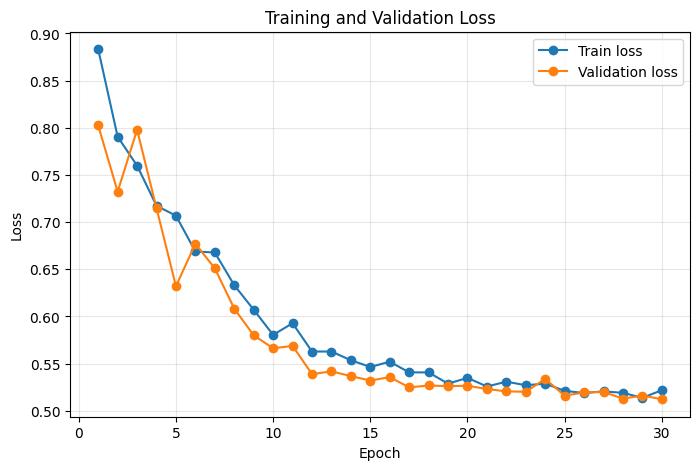

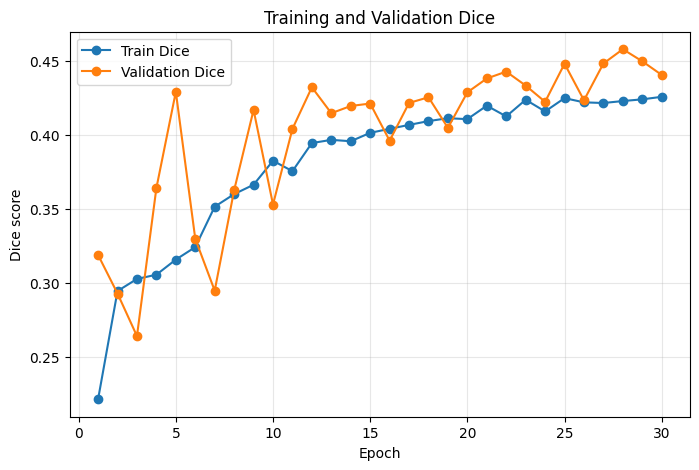

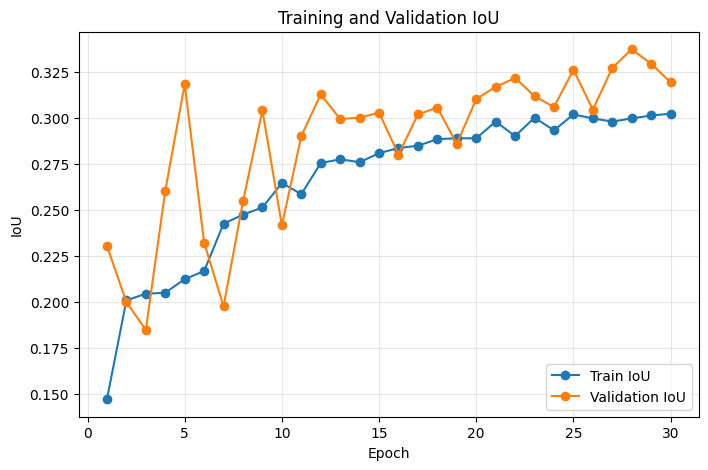

In [10]:
history_df = pd.DataFrame(history)
display(history_df)

# Loss curve
plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train loss")
plt.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Training and Validation Loss")
plt.grid(alpha=0.3); plt.legend(); plt.show()

# Dice curve
plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_dice"], marker="o", label="Train Dice")
plt.plot(history_df["epoch"], history_df["val_dice"], marker="o", label="Validation Dice")
plt.xlabel("Epoch"); plt.ylabel("Dice score"); plt.title("Training and Validation Dice")
plt.grid(alpha=0.3); plt.legend(); plt.show()

# IoU curve
plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_iou"], marker="o", label="Train IoU")
plt.plot(history_df["epoch"], history_df["val_iou"], marker="o", label="Validation IoU")
plt.xlabel("Epoch"); plt.ylabel("IoU"); plt.title("Training and Validation IoU")
plt.grid(alpha=0.3); plt.legend(); plt.show()

## 11. Threshold Calibration and Final Metrics

In [11]:
@torch.no_grad()
def evaluate_threshold(threshold):
    """Evaluate validation metrics at one probability threshold."""
    model.eval()
    total_loss = 0.0
    sums = {"dice": 0.0, "iou": 0.0, "precision": 0.0, "recall": 0.0}
    for x, y in val_loader:
        x, y = x.to(device), y.to(device)
        with torch.amp.autocast(device_type=device.type, enabled=USE_AMP):
            logits = model(x)
            loss = criterion(logits, y)
        m = batch_metrics(logits, y, threshold)
        total_loss += loss.item()
        for k in sums:
            sums[k] += m[k]
    n = max(len(val_loader), 1)
    out = {"threshold": threshold, "loss": total_loss/n}
    out.update({k: v/n for k, v in sums.items()})
    return out

thresholds = np.round(np.arange(0.20, 0.81, 0.05), 2)
threshold_records = []
for t in tqdm(thresholds, desc="Calibrating thresholds"):
    threshold_records.append(evaluate_threshold(float(t)))
threshold_df = pd.DataFrame(threshold_records)
display(threshold_df)

BEST_THRESHOLD = float(threshold_df.sort_values("dice", ascending=False).iloc[0]["threshold"])
print("Best threshold by validation Dice:", BEST_THRESHOLD)

final_metrics_df = pd.DataFrame([
    evaluate_threshold(DEFAULT_THRESHOLD),
    evaluate_threshold(BEST_THRESHOLD),
])
display(final_metrics_df)

Calibrating thresholds:   0%|          | 0/13 [00:00<?, ?it/s]

,threshold,loss,dice,iou,precision,recall
0,0.20,0.512317,0.359998,0.246616,0.265466,0.915325
1,0.25,0.512317,0.374952,0.259499,0.280080,0.906807
2,0.30,0.512317,0.388107,0.271019,0.292860,0.899343
3,0.35,0.512317,0.399548,0.281128,0.304875,0.892491
4,0.40,0.512317,0.416011,0.296525,0.322590,0.885881
5,0.45,0.512317,0.431522,0.311143,0.345973,0.878929
6,0.50,0.512317,0.440578,0.319523,0.357315,0.871307
7,0.55,0.512317,0.449141,0.327571,0.368915,0.862340
8,0.60,0.512317,0.470067,0.348134,0.393733,0.852064
9,0.65,0.512317,0.477997,0.355872,0.406888,0.840210


Best threshold by validation Dice: 0.8


,threshold,loss,dice,iou,precision,recall
0,0.5,0.512317,0.440578,0.319523,0.357315,0.871307
1,0.8,0.512317,0.507466,0.386278,0.465418,0.789731


## 12. Prediction Visualization

Each row shows image, ground truth, predicted probability map, thresholded prediction, and prediction overlay.

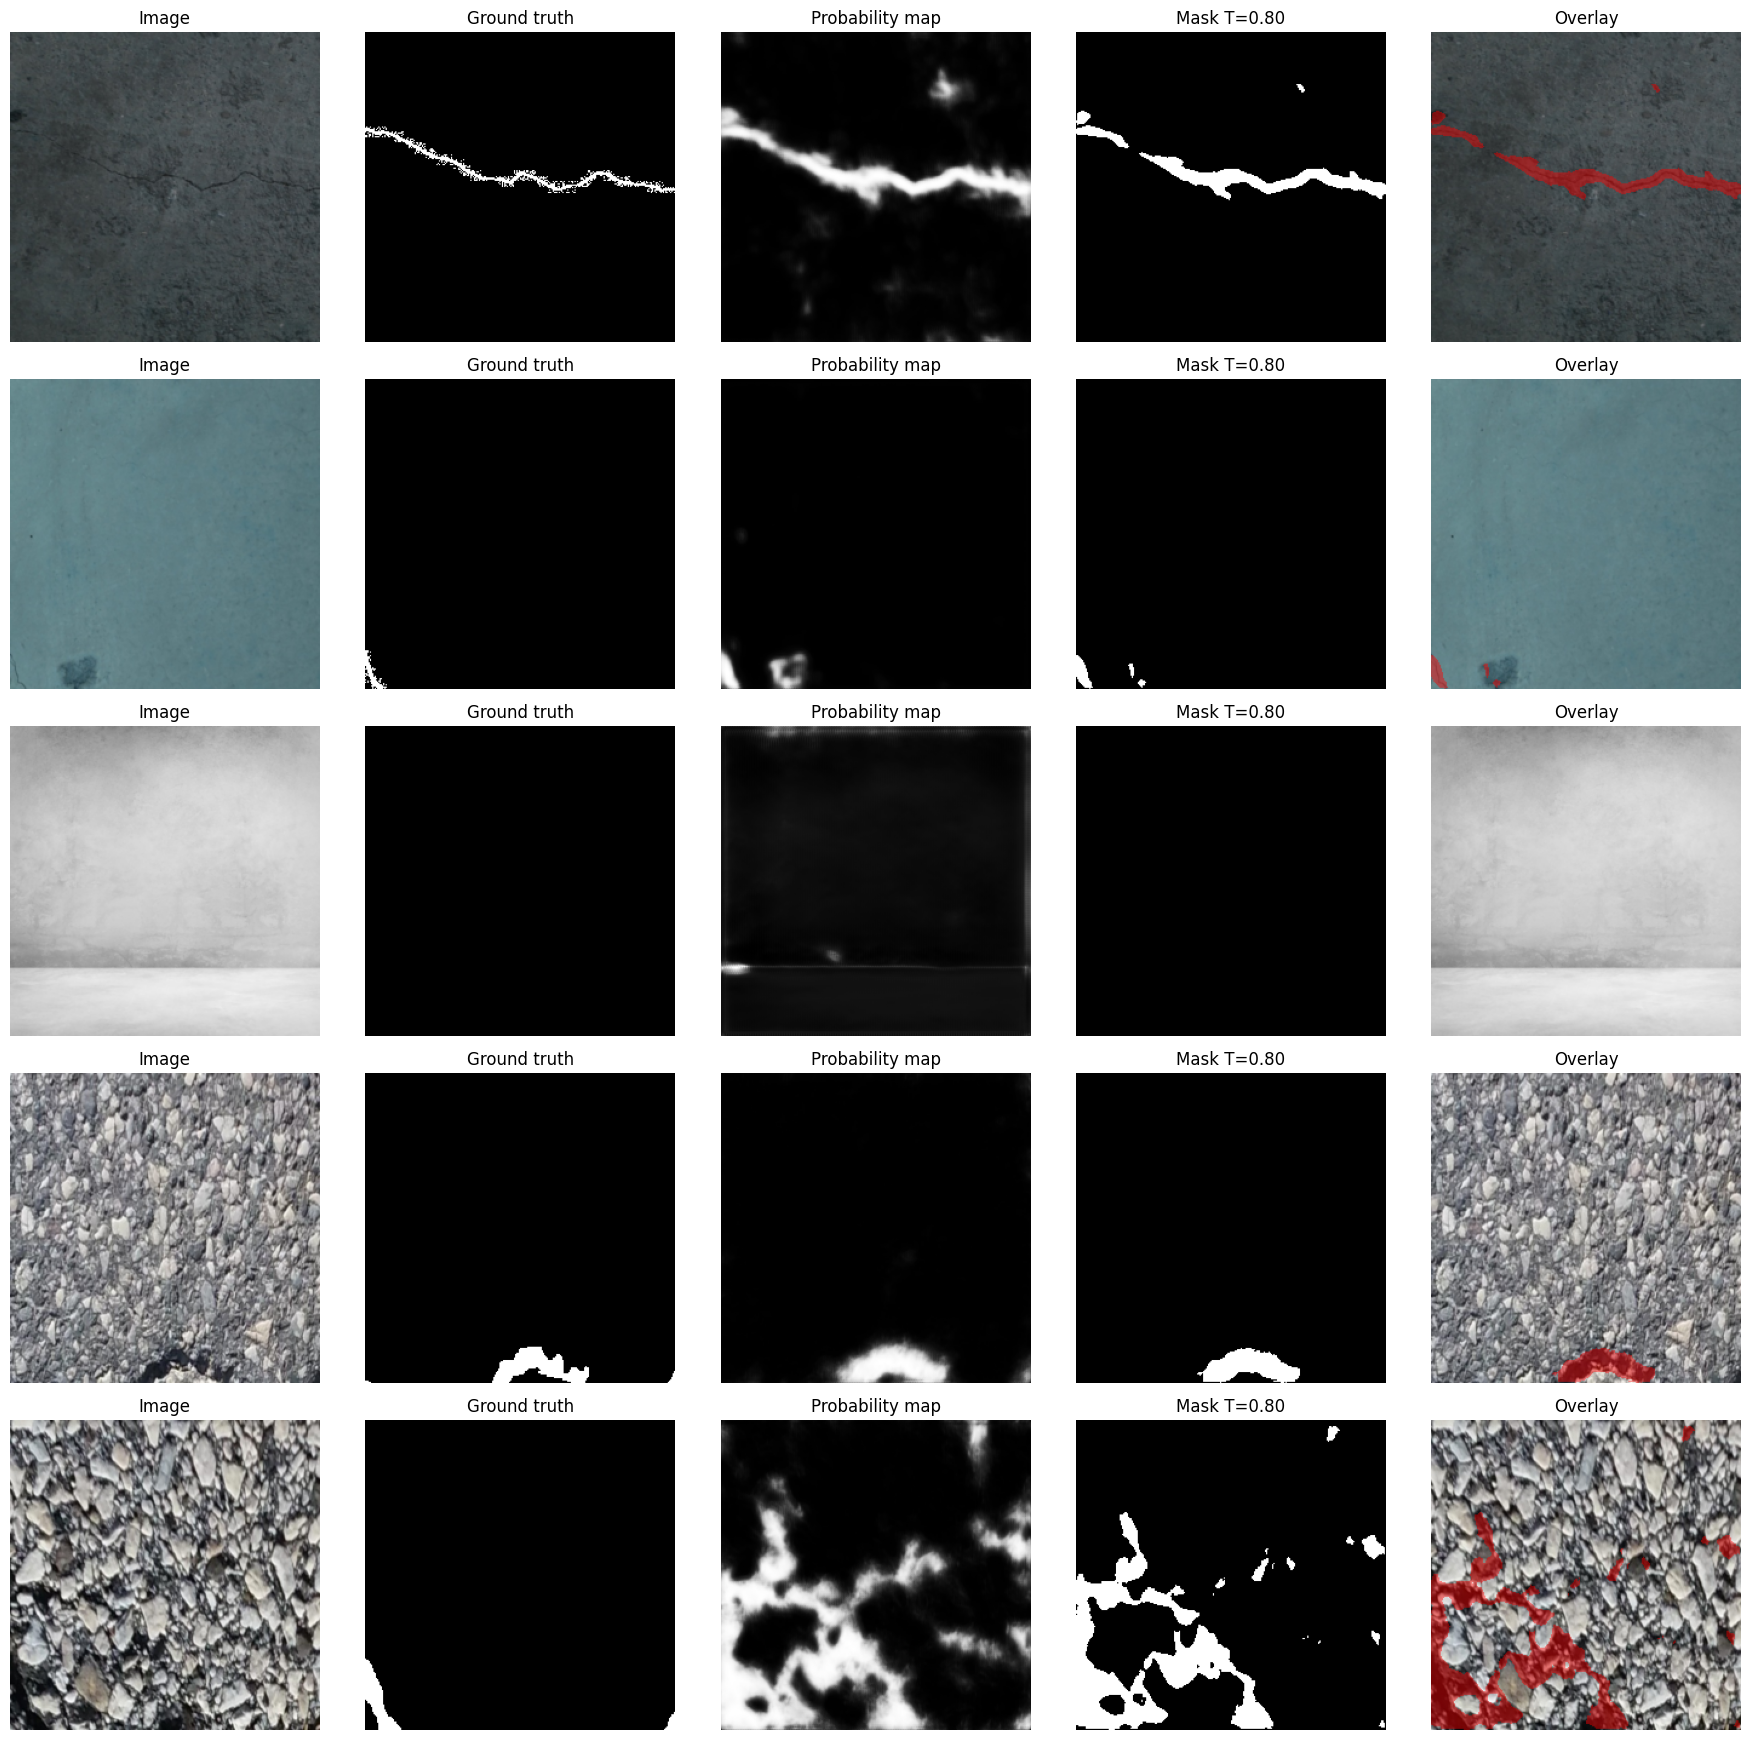

In [12]:
@torch.no_grad()
def get_prediction_batch():
    """Get one validation batch and model probabilities."""
    model.eval()
    x, y = next(iter(val_loader))
    with torch.amp.autocast(device_type=device.type, enabled=USE_AMP):
        logits = model(x.to(device))
    probs = torch.sigmoid(logits).cpu()
    return x.cpu(), y.cpu(), probs


def pred_overlay(image_tensor, mask_tensor, alpha=0.45):
    """Overlay predicted foreground pixels on the image."""
    img = (image_tensor.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    m = mask_tensor.squeeze().numpy() > 0.5
    red = img.copy()
    red[m] = [255, 0, 0]
    return (img * (1 - alpha) + red * alpha).astype(np.uint8)


def show_predictions(n=5, threshold=0.5):
    x, y, probs = get_prediction_batch()
    n = min(n, x.size(0))
    fig, axes = plt.subplots(n, 5, figsize=(18, 3.5 * n))
    if n == 1:
        axes = np.expand_dims(axes, 0)
    for i in range(n):
        pred = (probs[i] >= threshold).float()
        axes[i, 0].imshow(x[i].permute(1, 2, 0)); axes[i, 0].set_title("Image"); axes[i, 0].axis("off")
        axes[i, 1].imshow(y[i, 0], cmap="gray"); axes[i, 1].set_title("Ground truth"); axes[i, 1].axis("off")
        axes[i, 2].imshow(probs[i, 0], cmap="gray"); axes[i, 2].set_title("Probability map"); axes[i, 2].axis("off")
        axes[i, 3].imshow(pred[0], cmap="gray"); axes[i, 3].set_title(f"Mask T={threshold:.2f}"); axes[i, 3].axis("off")
        axes[i, 4].imshow(pred_overlay(x[i], pred)); axes[i, 4].set_title("Overlay"); axes[i, 4].axis("off")
    plt.tight_layout(); plt.show()

show_predictions(n=5, threshold=BEST_THRESHOLD)

## 13. Failure-Case Analysis

The following cells rank validation images by Dice score and display the weakest predictions.

Computing per-sample metrics:   0%|          | 0/160 [00:00<?, ?it/s]

,index,image_path,mask_path,dice,iou,precision,recall
113,113,/kaggle/input/datasets/lakshaymiddha/crack-seg...,/kaggle/input/datasets/lakshaymiddha/crack-seg...,1.244555e-11,1.244555e-11,1.244555e-11,1.000000e+00
12,12,/kaggle/input/datasets/lakshaymiddha/crack-seg...,/kaggle/input/datasets/lakshaymiddha/crack-seg...,1.689189e-11,1.689189e-11,1.689189e-11,1.000000e+00
125,125,/kaggle/input/datasets/lakshaymiddha/crack-seg...,/kaggle/input/datasets/lakshaymiddha/crack-seg...,1.705902e-11,1.705902e-11,1.705902e-11,1.000000e+00
84,84,/kaggle/input/datasets/lakshaymiddha/crack-seg...,/kaggle/input/datasets/lakshaymiddha/crack-seg...,2.092926e-11,2.092926e-11,3.855050e-11,4.578755e-11
81,81,/kaggle/input/datasets/lakshaymiddha/crack-seg...,/kaggle/input/datasets/lakshaymiddha/crack-seg...,3.080715e-11,3.080715e-11,3.080715e-11,1.000000e+00
55,55,/kaggle/input/datasets/lakshaymiddha/crack-seg...,/kaggle/input/datasets/lakshaymiddha/crack-seg...,3.523608e-11,3.523608e-11,3.523608e-11,1.000000e+00
130,130,/kaggle/input/datasets/lakshaymiddha/crack-seg...,/kaggle/input/datasets/lakshaymiddha/crack-seg...,5.431831e-11,5.431831e-11,5.431831e-11,1.000000e+00
8,8,/kaggle/input/datasets/lakshaymiddha/crack-seg...,/kaggle/input/datasets/lakshaymiddha/crack-seg...,5.552471e-11,5.552471e-11,5.552471e-11,1.000000e+00
20,20,/kaggle/input/datasets/lakshaymiddha/crack-seg...,/kaggle/input/datasets/lakshaymiddha/crack-seg...,9.624639e-11,9.624639e-11,9.624639e-11,1.000000e+00
138,138,/kaggle/input/datasets/lakshaymiddha/crack-seg...,/kaggle/input/datasets/lakshaymiddha/crack-seg...,1.215067e-10,1.215067e-10,1.000000e+00,1.215067e-10


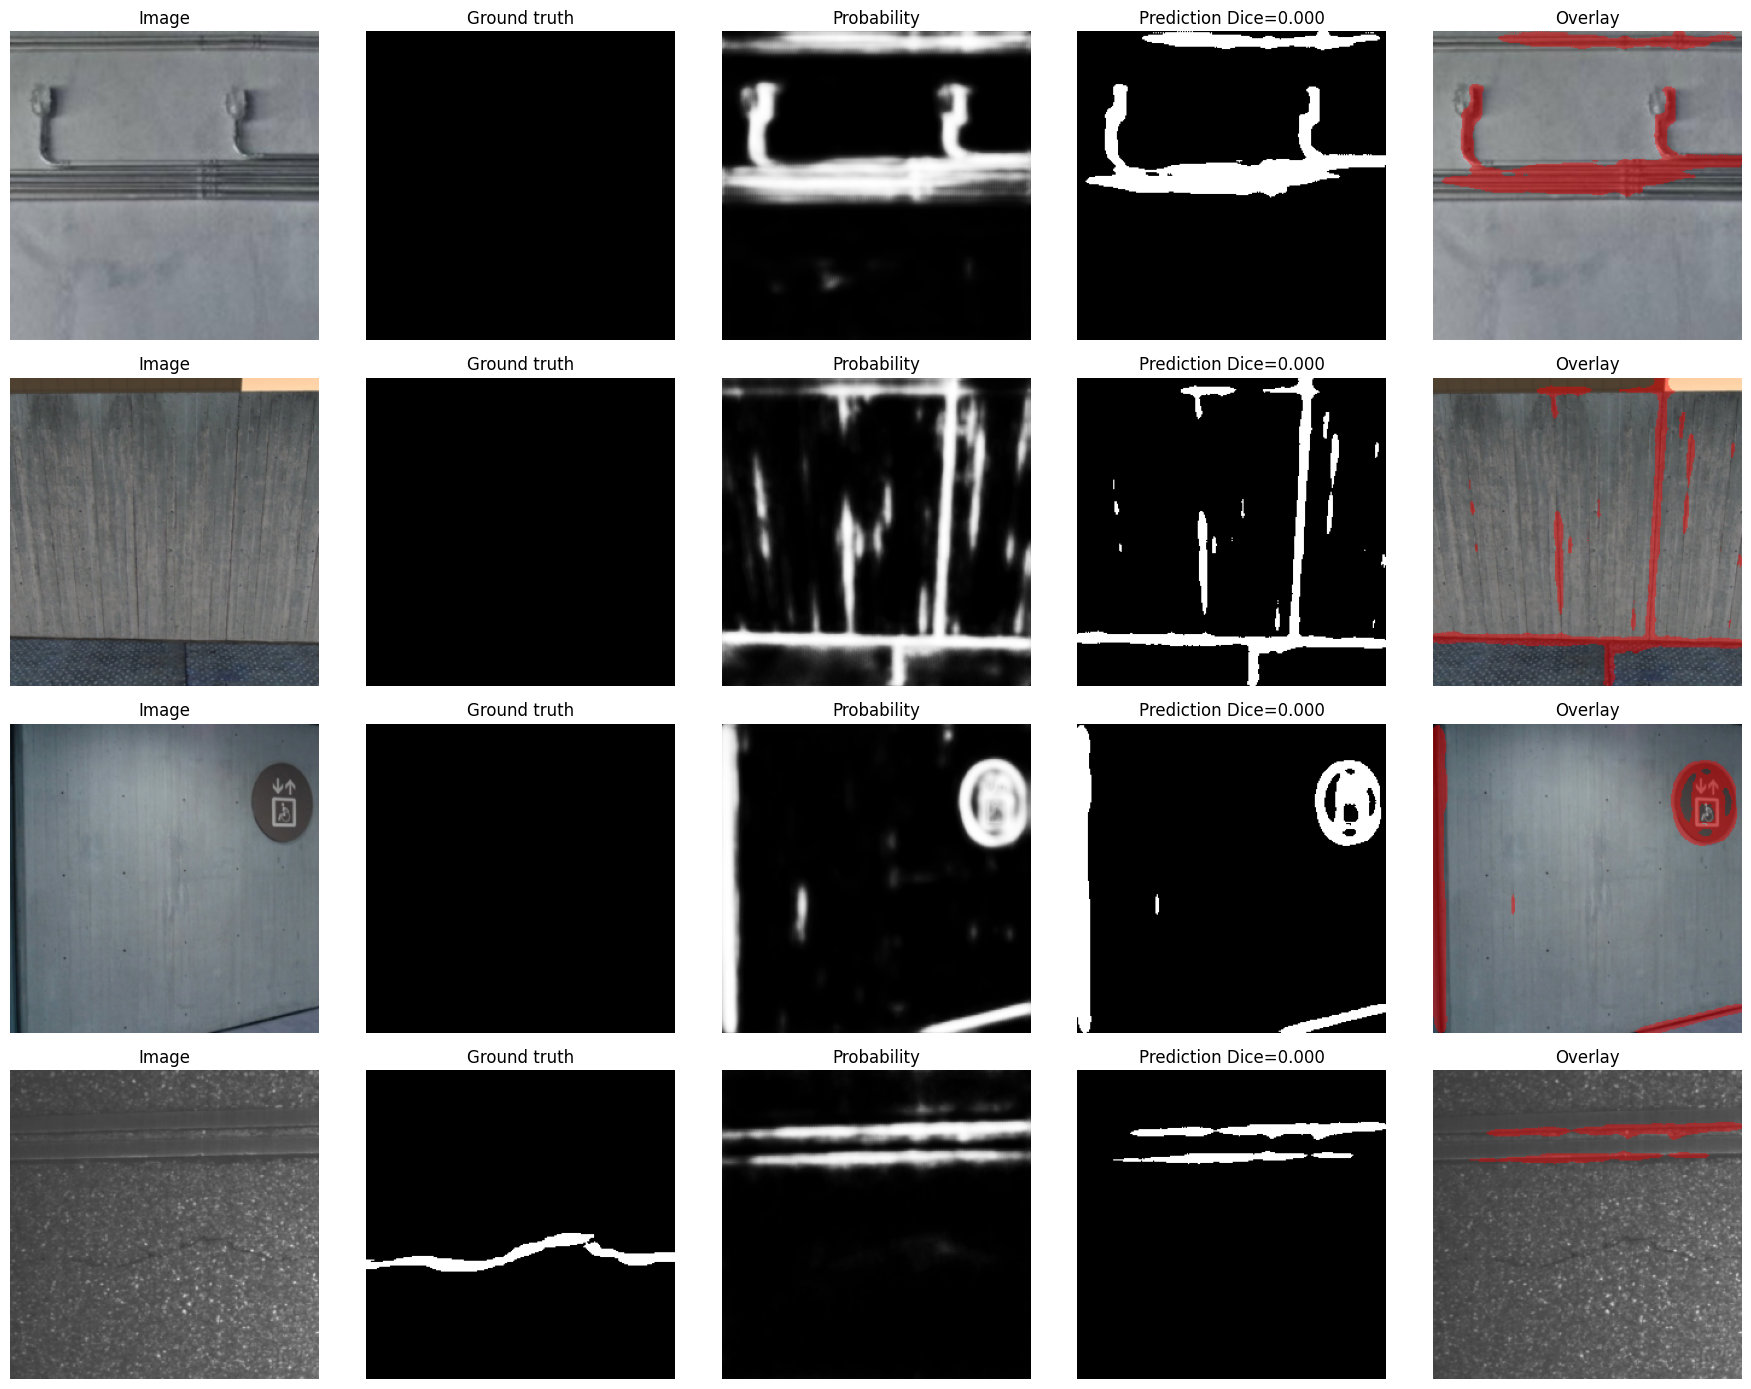

In [13]:
@torch.no_grad()
def per_sample_validation_metrics(threshold=0.5):
    """Compute Dice and IoU for each validation image."""
    model.eval()
    records = []
    one_loader = DataLoader(val_dataset, batch_size=1, shuffle=False, num_workers=0)
    for idx, (x, y) in enumerate(tqdm(one_loader, desc="Computing per-sample metrics")):
        x, y = x.to(device), y.to(device)
        with torch.amp.autocast(device_type=device.type, enabled=USE_AMP):
            logits = model(x)
        m = batch_metrics(logits, y, threshold)
        img_path, mask_path = val_dataset.pairs[idx]
        records.append({"index": idx, "image_path": str(img_path), "mask_path": str(mask_path), **m})
    return pd.DataFrame(records).sort_values("dice")

failure_df = per_sample_validation_metrics(BEST_THRESHOLD)
display(failure_df.head(10))


def show_failure_cases(n=4, threshold=0.5):
    """Display the worst validation predictions."""
    selected = failure_df.head(n)
    fig, axes = plt.subplots(len(selected), 5, figsize=(18, 3.5 * len(selected)))
    if len(selected) == 1:
        axes = np.expand_dims(axes, 0)
    model.eval()
    for r, (_, row) in enumerate(selected.iterrows()):
        idx = int(row["index"])
        x, y = val_dataset[idx]
        with torch.no_grad(), torch.amp.autocast(device_type=device.type, enabled=USE_AMP):
            prob = torch.sigmoid(model(x.unsqueeze(0).to(device))).cpu()[0]
        pred = (prob >= threshold).float()
        axes[r, 0].imshow(x.permute(1, 2, 0)); axes[r, 0].set_title("Image"); axes[r, 0].axis("off")
        axes[r, 1].imshow(y[0], cmap="gray"); axes[r, 1].set_title("Ground truth"); axes[r, 1].axis("off")
        axes[r, 2].imshow(prob[0], cmap="gray"); axes[r, 2].set_title("Probability"); axes[r, 2].axis("off")
        axes[r, 3].imshow(pred[0], cmap="gray"); axes[r, 3].set_title(f"Prediction Dice={row['dice']:.3f}"); axes[r, 3].axis("off")
        axes[r, 4].imshow(pred_overlay(x, pred)); axes[r, 4].set_title("Overlay"); axes[r, 4].axis("off")
    plt.tight_layout(); plt.show()

show_failure_cases(n=4, threshold=BEST_THRESHOLD)

## 14. Save Checkpoint, Metrics, and Optional Batch Mask Creation

In [14]:
OUTPUT_DIR = Path("/kaggle/working/seg03_unet_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = OUTPUT_DIR / "compact_unet_crack_segmentation.pt"
torch.save({
    "model_state_dict": model.state_dict(),
    "image_size": IMAGE_SIZE,
    "base_channels": BASE_CHANNELS,
    "best_threshold": BEST_THRESHOLD,
    "history": history,
}, checkpoint_path)

history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)
threshold_df.to_csv(OUTPUT_DIR / "threshold_calibration.csv", index=False)
final_metrics_df.to_csv(OUTPUT_DIR / "validation_metrics.csv", index=False)
print("Saved outputs to:", OUTPUT_DIR)


RUN_BATCH_MASK_CREATION = False

@torch.no_grad()
def batch_create_predicted_masks(image_paths, output_dir, threshold=0.5):
    """Create predicted binary masks for a list of images and save them as PNG files."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    model.eval()
    for img_path in tqdm(image_paths, desc="Creating predicted masks"):
        img_path = Path(img_path)
        original = Image.open(img_path).convert("RGB")
        original_size = original.size
        resized = TF.resize(original, [IMAGE_SIZE, IMAGE_SIZE], interpolation=TF.InterpolationMode.BILINEAR)
        x = TF.to_tensor(resized).unsqueeze(0).to(device)
        with torch.amp.autocast(device_type=device.type, enabled=USE_AMP):
            prob = torch.sigmoid(model(x)).cpu()[0, 0]
        pred = (prob.numpy() >= threshold).astype(np.uint8) * 255
        mask_img = Image.fromarray(pred, mode="L").resize(original_size, resample=Image.Resampling.NEAREST)
        mask_img.save(output_dir / f"{img_path.stem}_pred_mask.png")

if RUN_BATCH_MASK_CREATION:
    val_image_paths = [img for img, _ in val_pairs]
    batch_create_predicted_masks(val_image_paths, OUTPUT_DIR / "predicted_masks", threshold=BEST_THRESHOLD)
else:
    print("Batch mask creation is disabled. Set RUN_BATCH_MASK_CREATION = True to create predicted masks.")

Saved outputs to: /kaggle/working/seg03_unet_outputs
Batch mask creation is disabled. Set RUN_BATCH_MASK_CREATION = True to create predicted masks.


## 15. Improvement Notes

This notebook provides a compact baseline. To improve results, train on the full dataset, increase input resolution, use a stronger encoder, add crack-preserving augmentations, tune the combined loss, calibrate thresholds on a separate validation split, and compare results against SEG01 and SEG02 baselines.